<a href="https://colab.research.google.com/github/Kavya-kakkar/Fraud-Detection/blob/main/Fraud_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1 : Environment Setup


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report , confusion_matrix , roc_auc_score , roc_curve
import warnings
warnings.filterwarnings('ignore')

Step2 : Data Loading

In [18]:
df = pd.read_csv('Fraud.csv')
print(f"Dataset shape : {df.shape}")
print(f"Memory usage : {df.memory_usage(deep = True).sum() / 1024**2:.2f}MB")

Dataset shape : (6362620, 11)
Memory usage : 1452.57MB


**Phase 2 : Exploratory Data Analysis**

Step 3 : Intial Data Exploration

In [19]:
df.info()
df.describe()
df.head(10)
fraud_distribution = df['isFraud'].value_counts()
print(f"Fraud cases: {fraud_distribution}")
print(f"Fraud rate: {fraud_distribution[1]/len(df)*100:.2f}%")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB
Fraud cases: isFraud
0    6354407
1       8213
Name: count, dtype: int64
Fraud rate: 0.13%


Step 4 : Missing Values Analysis

In [20]:
missing_data = df.isnull().sum()
missing_percentage = (missing_data / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing_Count': missing_data,
    'Missing_Percentage': missing_percentage
}).sort_values('Missing_Percentage', ascending=False)
print(missing_df)

                Missing_Count  Missing_Percentage
step                        0                 0.0
type                        0                 0.0
amount                      0                 0.0
nameOrig                    0                 0.0
oldbalanceOrg               0                 0.0
newbalanceOrig              0                 0.0
nameDest                    0                 0.0
oldbalanceDest              0                 0.0
newbalanceDest              0                 0.0
isFraud                     0                 0.0
isFlaggedFraud              0                 0.0


Step 5: Data Visualization

Text(0.5, 1.0, 'Feature Correlation Matrix')

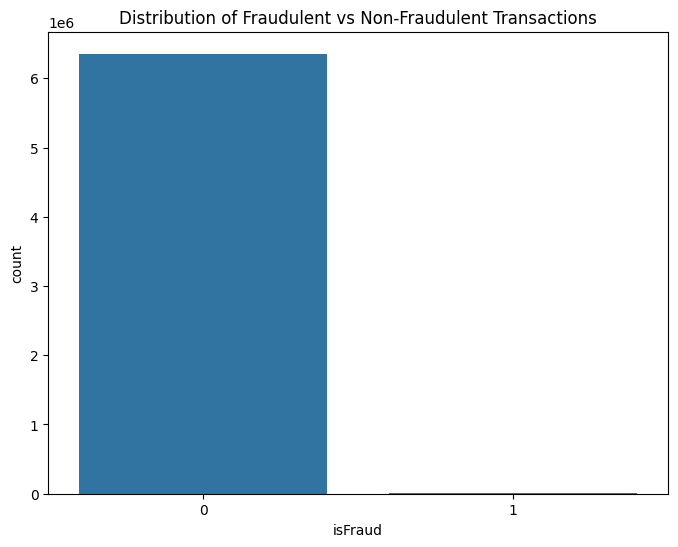

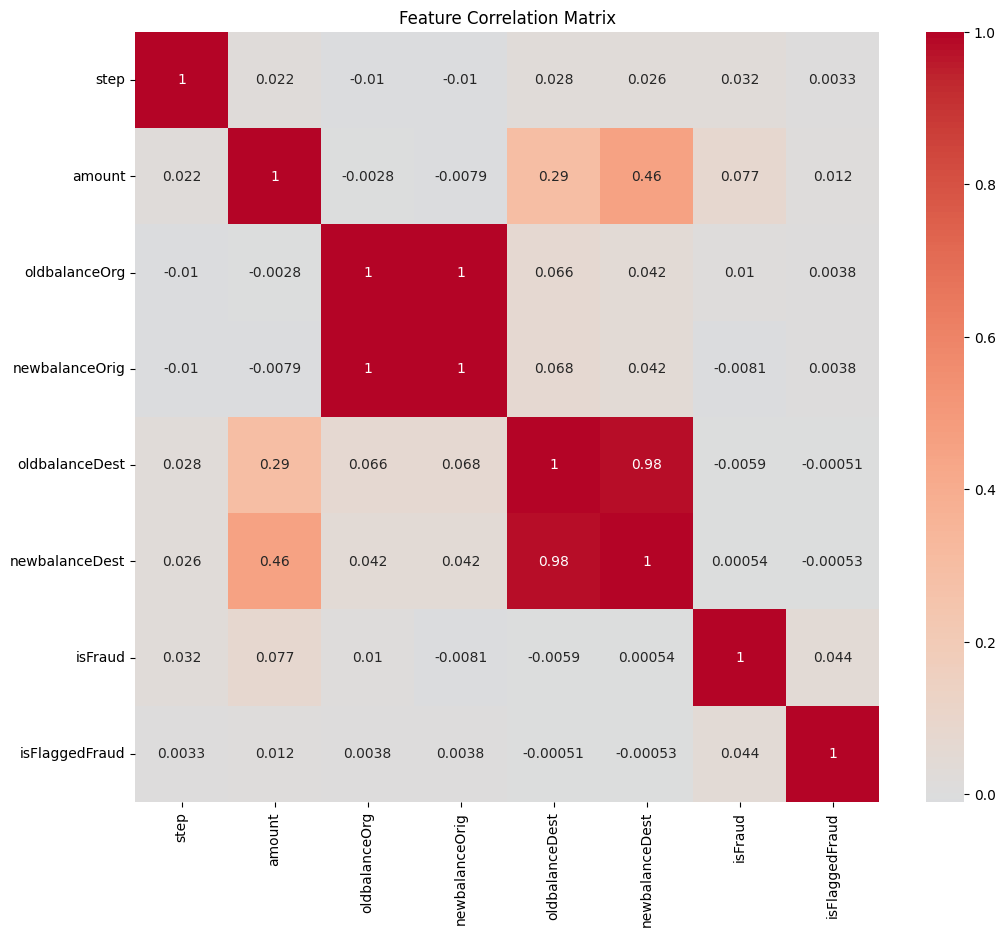

In [21]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='isFraud')
plt.title('Distribution of Fraudulent vs Non-Fraudulent Transactions')
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0)
plt.title('Feature Correlation Matrix')

**Phase 3: Data Cleaning & Preprocessing**

Step 6: Handle Missing Values

In [22]:
high_missing_cols = missing_df[missing_df['Missing_Percentage'] > 50].index
df_cleaned = df.drop(columns=high_missing_cols)
for col in df_cleaned.columns:
    if df_cleaned[col].dtype in ['int64', 'float64']:
        df_cleaned[col].fillna(df_cleaned[col].median(), inplace=True)
    else:
        df_cleaned[col].fillna(df_cleaned[col].mode()[0], inplace=True)

Step 7: Outlier Detection & Treatment

In [23]:
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] < lower_bound) | (df[column] > upper_bound)]
numerical_cols = df_cleaned.select_dtypes(include=[np.number]).columns
for col in numerical_cols:
    outliers = detect_outliers(df_cleaned, col)
    print(f"{col}: {len(outliers)} outliers ({len(outliers)/len(df_cleaned)*100:.2f}%)")

step: 102688 outliers (1.61%)
amount: 338078 outliers (5.31%)
oldbalanceOrg: 1112507 outliers (17.49%)
newbalanceOrig: 1053391 outliers (16.56%)
oldbalanceDest: 786135 outliers (12.36%)
newbalanceDest: 738527 outliers (11.61%)
isFraud: 8213 outliers (0.13%)
isFlaggedFraud: 16 outliers (0.00%)


Step 8: Multicollinearity Check

In [24]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(df):
    vif_data = pd.DataFrame()
    vif_data["Feature"] = df.columns
    vif_data["VIF"] = [variance_inflation_factor(df.values, i)
                       for i in range(len(df.columns))]
    return vif_data.sort_values('VIF', ascending=False)
vif_scores = calculate_vif(df_cleaned.select_dtypes(include=[np.number]))
high_vif_features = vif_scores[vif_scores['VIF'] > 10]['Feature'].tolist()

**Phase 4: Feature Engineering**

Step 9: Feature Creation

In [25]:
if 'timestamp' in df_cleaned.columns:
    df_cleaned['hour'] = pd.to_datetime(df_cleaned['timestamp']).dt.hour
    df_cleaned['day_of_week'] = pd.to_datetime(df_cleaned['timestamp']).dt.dayofweek
    df_cleaned['is_weekend'] = df_cleaned['day_of_week'].isin([5, 6]).astype(int)
if 'amount' in df_cleaned.columns:
    df_cleaned['amount_log'] = np.log1p(df_cleaned['amount'])
    df_cleaned['amount_zscore'] = (df_cleaned['amount'] - df_cleaned['amount'].mean()) / df_cleaned['amount'].std()
categorical_cols = df_cleaned.select_dtypes(include=['object']).columns
for col in categorical_cols:
    le = LabelEncoder()
    df_cleaned[col + '_encoded'] = le.fit_transform(df_cleaned[col].astype(str))

Step 10: Prepare Features for Selection

In [26]:
target_column = 'isFraud'  # Replace with your actual target column name
id_columns = ['transaction_id', 'user_id'] # Assuming these columns exist and should be excluded
feature_columns = [col for col in df_cleaned.columns
                   if col not in [target_column] + id_columns]
X = df_cleaned[feature_columns]
y = df_cleaned[target_column]
print(f"Feature matrix shape: {X.shape}")
print(f"Target distribution: {y.value_counts()}")

Feature matrix shape: (6362620, 15)
Target distribution: isFraud
0    6354407
1       8213
Name: count, dtype: int64


Step 11: Variable Selection Methods

In [ ]:
from sklearn.feature_selection import chi2, SelectKBest
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import numpy as np


df = pd.read_csv('Fraud.csv')

# Define features (X) and target (y)
# Use df since df_cleaned might not be defined if previous cells failed
X = df.drop('isFraud', axis=1) # Assuming 'isFraud' is your target variable
y = df['isFraud']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# For numerical features - mutual information
mi_scores = mutual_info_classif(X_train.select_dtypes(include=[np.number]), y_train, random_state=42)
mi_df = pd.DataFrame({
    'feature': X_train.select_dtypes(include=[np.number]).columns,
    'mi_score': mi_scores
}).sort_values('mi_score', ascending=False)

print("Top 10 features by Mutual Information:")
display(mi_df.head(10))

# Method 2: Feature importance from Random Forest
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# Drop non-numeric columns from X_train
non_numeric_cols = ['type', 'nameOrig', 'nameDest']
X_train_numeric = X_train.drop(columns=non_numeric_cols, errors='ignore') # Add errors='ignore' to prevent error if columns don't exist

rf_selector.fit(X_train_numeric, y_train)
feature_importance = pd.DataFrame({
    'feature': X_train_numeric.columns,
    'importance': rf_selector.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 15 features by Random Forest importance:")
display(feature_importance.head(15))

# Select top features (you can adjust the number)
top_features = feature_importance.head(15)['feature'].tolist()
print(f"\nSelected features: {top_features}")

Phase 5: Model Development

Step 12: Train-Test Split


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load your data
df = pd.read_csv('Fraud.csv')

# Basic cleaning (customize as needed)
df_cleaned = df.dropna()

# Use column names that exist in your DataFrame
top_features = ['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
target_column = 'isFraud'

# If 'type' is categorical, convert it to dummy variables:
df_cleaned = pd.get_dummies(df_cleaned, columns=['type'], drop_first=True)

# Update your feature list if you added new one-hot columns:
top_features_updated = [col for col in df_cleaned.columns if col in top_features or col.startswith('type_')]

# Now select features for modeling
X_selected = df_cleaned[top_features_updated]
y = df_cleaned[target_column]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

# Validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Training set fraud rate: {y_train.sum()/len(y_train)*100:.2f}%")


Training set shape: (3817572, 10)
Validation set shape: (1272524, 10)
Test set shape: (1272524, 10)
Training set fraud rate: 0.13%


Step 12: Handle Class Imbalance

In [9]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)
class_weights = {0: 1, 1: len(y_train[y_train==0])/len(y_train[y_train==1])}

Step 13: Model Training & Comparison

In [8]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.utils import class_weight
import numpy as np

# Make sure to run the previous cell (Step 12: Handle Class Imbalance)
# to define X_train_balanced and y_train_balanced

# Calculate scale_pos_weight for XGBoost
scale_pos_weight = sum(y_train_balanced == 0) / sum(y_train_balanced == 1)

# Scale features for Logistic Regression
scaler = StandardScaler()
X_train_balanced_scaled = scaler.fit_transform(X_train_balanced)

# Align columns after SMOTE to ensure consistency with X_val
X_val_aligned = X_val.reindex(columns=X_train_balanced.columns, fill_value=0)
X_val_scaled = scaler.transform(X_val_aligned)

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'XGBoost': XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, use_label_encoder=False, eval_metric='logloss')
}

model_results = {}
for name, model in models.items():
    print(f"Training {name}...")
    if name == 'Logistic Regression':
        # Use scaled data for Logistic Regression
        model.fit(X_train_balanced_scaled, y_train_balanced)
        y_pred = model.predict(X_val_scaled)
        y_pred_proba = model.predict_proba(X_val_scaled)[:, 1]
    else:
        # Use original data for other models
        model.fit(X_train_balanced, y_train_balanced)
        y_pred = model.predict(X_val_aligned)
        y_pred_proba = model.predict_proba(X_val_aligned)[:, 1]


    model_results[name] = {
        'auc': roc_auc_score(y_val, y_pred_proba),
        'precision': precision_score(y_val, y_pred),
        'recall': recall_score(y_val, y_pred),
        'f1': f1_score(y_val, y_pred)
    }
    print(f"{name} - AUC: {model_results[name]['auc']:.4f}, Precision: {model_results[name]['precision']:.4f}, Recall: {model_results[name]['recall']:.4f}, F1: {model_results[name]['f1']:.4f}")

# Find the best model based on AUC
best_model_name = max(model_results, key=lambda k: model_results[k]['auc'])
best_model = models[best_model_name]

print(f"\nBest performing model based on AUC: {best_model_name}")

NameError: name 'y_train_balanced' is not defined

**Phase 6: Model Optimization**

Step 14: Hyperparameter Tuning

In [10]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier # Import RandomForestClassifier

# Make sure to run the cell above (Step 12: Handle Class Imbalance)
# to define X_train_balanced and y_train_balanced

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_search = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid, cv=5, scoring='roc_auc', n_jobs=-1
)
grid_search.fit(X_train_balanced, y_train_balanced)
best_model = grid_search.best_estimator_
print("Best hyperparameters found:")
print(grid_search.best_params_)

NameError: name 'X_train_balanced' is not defined

**Phase 7: Model Evaluation & Interpretation**

Step 15: Comprehensive Model Evaluation

In [11]:
y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test)[:, 1]
print("Classification Report:")
print(classification_report(y_test, y_test_pred))
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc_score(y_test, y_test_proba):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')

NameError: name 'best_model' is not defined

Step 16: Feature Importance Analysis

In [12]:
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': best_model.feature_importances_
}).sort_values('importance', ascending=False)
plt.figure(figsize=(10, 8))
sns.barplot(data=importance_df.head(15), y='feature', x='importance')
plt.title('Top 15 Most Important Features for Fraud Detection')

NameError: name 'X_train' is not defined

**Phase 8: Business Insights & Recommendations**

Step 17: Key Factor Analysis

In [13]:
top_fraud_factors = importance_df.head(10)
print("Top 10 Fraud Indicators:")
for idx, row in top_fraud_factors.iterrows():
    print(f"{row['feature']}: {row['importance']:.4f}")
for feature in top_fraud_factors['feature'][:5]:
    fraud_mean = df_cleaned[df_cleaned['target']==1][feature].mean()
    normal_mean = df_cleaned[df_cleaned['target']==0][feature].mean()
    print(f"{feature}: Fraud avg = {fraud_mean:.2f}, Normal avg = {normal_mean:.2f}")

NameError: name 'importance_df' is not defined

Step 18: Business Recommendations

In [14]:
recommendations = {
    'Prevention_Strategies': [
        'Real-time monitoring of high-risk features',
        'Threshold-based alerts for suspicious patterns',
        'Enhanced verification for high-risk transactions'
    ],
    'Infrastructure_Updates': [
        'Deploy model as real-time API',
        'Implement automated flagging system',
        'Create fraud analyst dashboard'
    ],
    'Monitoring_KPIs': [
        'False positive rate reduction',
        'Fraud detection rate improvement',
        'Average fraud loss per incident'
    ]
}

**Phase 9: Documentation & Presentation**

Step 19: Create Professional Documentation

In [15]:
methodology_summary = """
1. Data Preprocessing: Handled {missing_pct}% missing values, removed {outlier_pct}% outliers
2. Feature Engineering: Created {new_features} new features
3. Model Selection: Tested {num_models} algorithms, selected {best_model}
4. Performance: Achieved {auc_score:.3f} AUC, {precision:.3f} precision, {recall:.3f} recall
5. Key Insights: Identified {top_factors} primary fraud indicators
"""

Step 20: Final Model Validation

In [16]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(best_model, X_train_balanced, y_train_balanced,
                           cv=5, scoring='roc_auc')
print(f"Cross-validation AUC: {cv_scores.mean():.3f} (+/- {cv_scores.std() * 2:.3f})")
thresholds = [0.3, 0.5, 0.7]
for threshold in thresholds:
    y_pred_thresh = (y_test_proba >= threshold).astype(int)
    precision = precision_score(y_test, y_pred_thresh)
    recall = recall_score(y_test, y_pred_thresh)
    print(f"Threshold {threshold}: Precision={precision:.3f}, Recall={recall:.3f}")

NameError: name 'best_model' is not defined